# Wave-2 results report
Presentation only: every number below is read from `wave2/results`, `wave2/extracts` or `wave2/external`; nothing is re-estimated except the quantities named in each section (placebo, H2 mid-quote decomposition, H1 CIs). Dev period 2022-01-03 to 2024-06-28; holdout 2024-07-01 to 2024-12-31 (shaded grey in time-series figures). Returns are daily excess returns on a $1M reference account unless stated.

Figure style: NeurIPS-2025 plot style guide via `research_style.py` (white background, open spines, dashed light grid, markers on lines, black flat-capped error bars, one colour per strategy, out-of-sample periods in a light grey band labelled *holdout*). Each figure is preceded by its single-sentence message, and each saved PNG was checked against the guide.

In [1]:
import sys, warnings, glob, pathlib
ROOT = pathlib.Path('/Users/nigelli/Desktop/lp work')
sys.path.insert(0, str(ROOT / 'wave2'))
import analysis
sys.path.insert(0, str(ROOT))
import research_style as rs
rs.setup()
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt, matplotlib.dates as mdates
from IPython.display import Markdown, display
warnings.filterwarnings('ignore')
W = ROOT / 'wave2'; RES = W / 'results'; EXT = W / 'extracts'; FIG = W / 'figures'; FIG.mkdir(exist_ok=True)

# one colour per strategy, shared with every other figure (research_style.py)
COL = dict(rs.STRAT_COL, F1='#7A7A7A')
DEV_COL = rs.DEV_COL; HOLD_COL = rs.OOS_COL
NOTES = {}   # figure name -> (takeaway, checks)
def save(fig, name):
    rs.save(fig, FIG / name); plt.show()
def todt(x): return pd.to_datetime(pd.Series(x).astype(str), format='%Y%m%d')
def shade(ax, xmax=None):
    rs.shade_test(ax, pd.Timestamp('2024-07-01'), pd.Timestamp('2024-12-31'), 'holdout')
def say(name, text, check=''):
    NOTES[name] = (text, check); display(Markdown(text + (f'\n\n*Data check:* {check}' if check else '')))
SC = pd.read_csv(RES / 'scorecard_daily.csv'); DEC = pd.read_csv(RES / 'decisions.csv')
print('wave-2 report ready; DEV_END =', analysis.DEV_END)

wave-2 report ready; DEV_END = 20240628


## 1. Fill funnel: how much of each design was executable

**Figure 1 message:** only H1, H3, H4 and H6 (and the amended A1/A4 variants) filled most attempts; the pre-registered H2 and H5 primaries filled 1% of attempts.

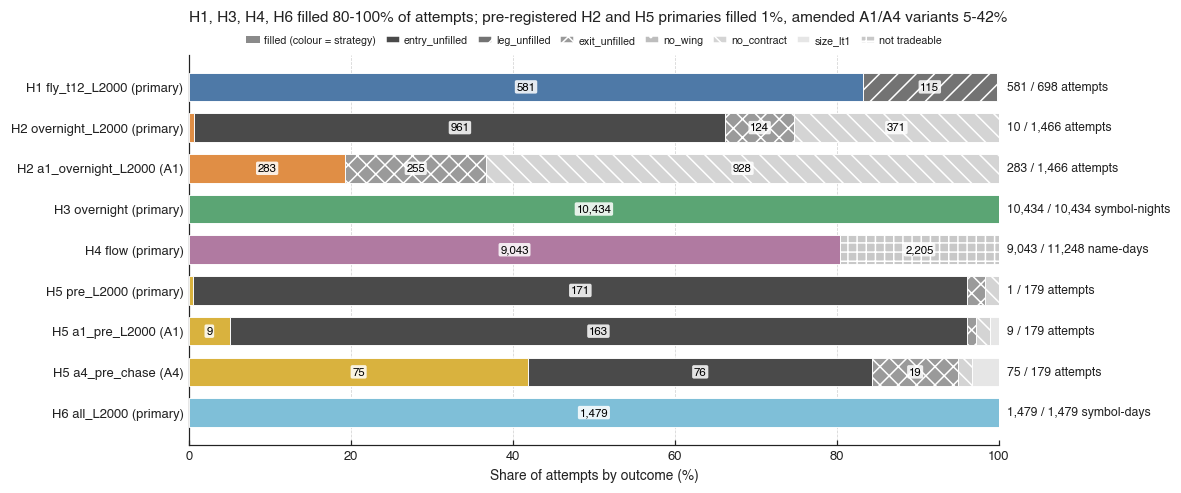

In [2]:
specs = [('H1','h1','fly_t12_L2000','H1 fly_t12_L2000 (primary)'),
         ('H2','h2','overnight_L2000','H2 overnight_L2000 (primary)'),
         ('H2','h2','a1_overnight_L2000','H2 a1_overnight_L2000 (A1)'),
         ('H3','h3','overnight','H3 overnight (primary)'),
         ('H4','h4','flow','H4 flow (primary)'),
         ('H5','h5','pre_L2000','H5 pre_L2000 (primary)'),
         ('H5','h5','a1_pre_L2000','H5 a1_pre_L2000 (A1)'),
         ('H5','h5','a4_pre_chase','H5 a4_pre_chase (A4)'),
         ('H6','h6','all_L2000','H6 all_L2000 (primary)')]
rows = []
for fam, h, v, lab in specs:
    if h in ('h1','h2','h5'):
        t = pd.read_csv(RES / f'{h}_trades.csv'); s = t[t.variant == v].status
        vc = s.where(~s.str.startswith('filled'), 'filled').value_counts()
        unit = 'attempts'
    elif h == 'h3':
        t = pd.read_csv(RES / 'h3_trades.csv'); n = (t.variant == v).sum(); vc = pd.Series({'filled': n}); unit = 'symbol-nights'
    elif h == 'h6':
        t = pd.read_csv(RES / 'h6_trades.csv'); n = (t.variant == v).sum(); vc = pd.Series({'filled': n}); unit = 'symbol-days'
    else:
        t = pd.read_csv(RES / 'h4_trades.csv'); vc = t.tradeable.map({1: 'filled', 0: 'not tradeable'}).value_counts(); unit = 'name-days'
    rows.append((fam, lab, vc.to_dict(), unit))
reasons = ['entry_unfilled','leg_unfilled','exit_unfilled','no_wing','no_contract','size_lt1','filtered','not tradeable']
gray = dict(zip(reasons, ['#4a4a4a','#737373','#9a9a9a','#bdbdbd','#d4d4d4','#e6e6e6','#f0f0f0','#c8c8c8']))
hatch = dict(zip(reasons, ['','//','xx','..','\\\\','','--','++']))
fig, ax = plt.subplots(figsize=(9.5, 4.6))
for i, (fam, lab, d, unit) in enumerate(rows[::-1]):
    tot = sum(d.values()); left = 0
    for k in ['filled'] + [r for r in reasons if r in d]:
        if k not in d: continue
        w = d[k] / tot * 100
        ax.barh(i, w, left=left, color=COL[fam] if k == 'filled' else gray[k], hatch=hatch.get(k, ''), edgecolor='white', lw=.6, height=.7, zorder=3)
        if w >= 4: ax.text(left + w / 2, i, f'{d[k]:,}', ha='center', va='center', fontsize=7.5, color='black', zorder=5, bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=.85))
        left += w
    ax.text(101, i, f"{d.get('filled',0):,} / {tot:,} {unit}", va='center', fontsize=8)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[1] for r in rows[::-1]])
ax.set_xlim(0, 100); ax.set_xlabel('Share of attempts by outcome (%)'); ax.grid(axis='y', visible=False)
from matplotlib.patches import Patch
hs = [Patch(facecolor='#8a8a8a', label='filled (colour = strategy)')] + [Patch(facecolor=gray[r], hatch=hatch[r], edgecolor='white', label=r) for r in reasons if any(r in d for _,_,d,_ in rows)]
ax.legend(handles=hs, loc='lower center', bbox_to_anchor=(.5, 1.0), ncol=len(hs), frameon=False, fontsize=7, columnspacing=.9, handlelength=1.3, handletextpad=.4)
ax.set_title('H1, H3, H4, H6 filled 80-100% of attempts; pre-registered H2 and H5 primaries filled 1%, amended A1/A4 variants 5-42%', pad=22)
save(fig, 'fig01_fill_funnel.png')


In [3]:
txt = '; '.join(f"{lab}: {d.get('filled',0):,} of {sum(d.values()):,} ({d.get('filled',0)/sum(d.values()):.0%}) filled" for _,lab,d,_ in rows)
say('fig01_fill_funnel.png', 'Filled share by design (H3/H6 list only executed rows; H4 uses the `tradeable` flag): ' + txt + '.')

Filled share by design (H3/H6 list only executed rows; H4 uses the `tradeable` flag): H1 fly_t12_L2000 (primary): 581 of 698 (83%) filled; H2 overnight_L2000 (primary): 10 of 1,466 (1%) filled; H2 a1_overnight_L2000 (A1): 283 of 1,466 (19%) filled; H3 overnight (primary): 10,434 of 10,434 (100%) filled; H4 flow (primary): 9,043 of 11,248 (80%) filled; H5 pre_L2000 (primary): 1 of 179 (1%) filled; H5 a1_pre_L2000 (A1): 9 of 179 (5%) filled; H5 a4_pre_chase (A4): 75 of 179 (42%) filled; H6 all_L2000 (primary): 1,479 of 1,479 (100%) filled.

## 2. F1 execution-cost atlas

**Figure 2 message:** the effective half-spread is mostly below the quoted half-spread (ratio < 1), and relative quoted spreads in SPXW, SPY and QQQ rise into the close.

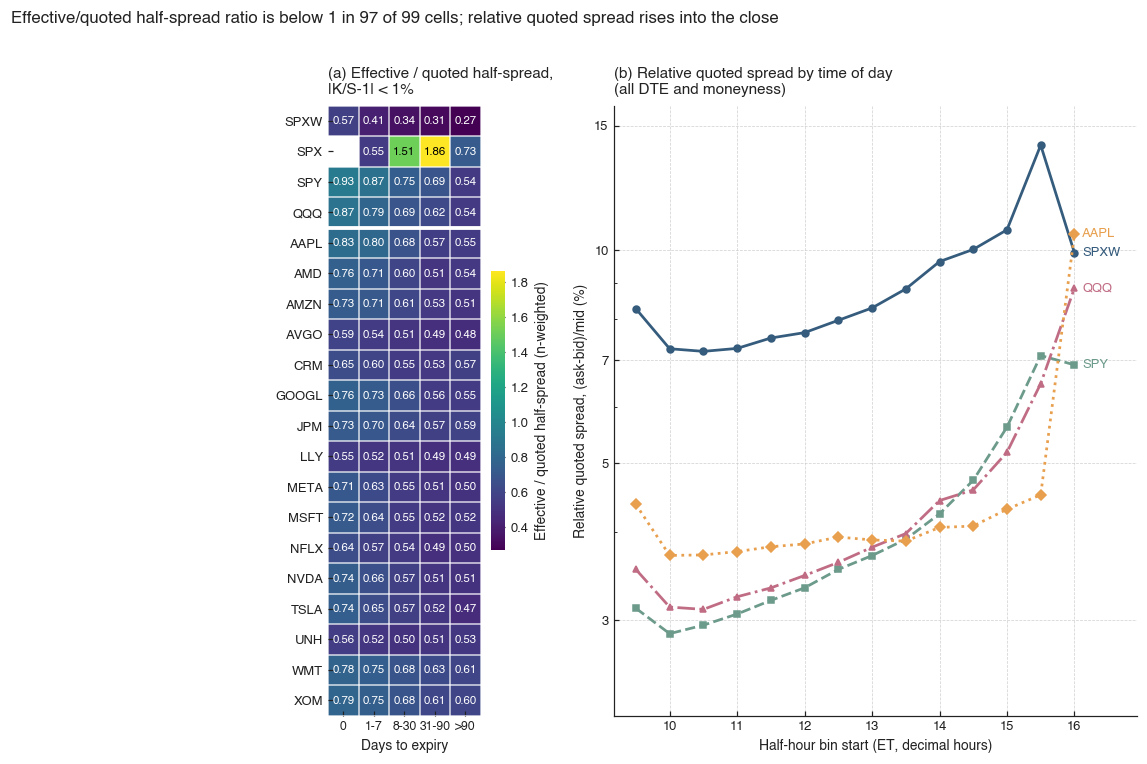

In [4]:
at = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(str(EXT / 'f1_atlas_*.csv')))])
def wmean(g, c): return np.average(g[c], weights=g.n)
sub = at[at.mny_b == '<1%']
hm = sub.groupby(['root','dte_b']).apply(lambda g: wmean(g, 'eff_ratio')).unstack()
dte_order = ['0','1-7','8-30','31-90','>90']; hm = hm[dte_order]
singles = sorted([r for r in hm.index if r not in ('SPXW','SPX','SPY','QQQ')])
hm = hm.loc[['SPXW','SPX','SPY','QQQ'] + singles]
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 7.2), gridspec_kw=dict(width_ratios=[1, 1.5], wspace=.25))
vmin, vmax = np.nanmin(hm.values), np.nanmax(hm.values)
im = a.imshow(hm.values, cmap='viridis', aspect='equal', vmin=vmin, vmax=vmax)
a.set_xticks(range(5)); a.set_xticklabels(dte_order, fontsize=8); a.set_yticks(range(len(hm))); a.set_yticklabels(hm.index); a.grid(False)
a.set_xticks(np.arange(-.5, 5, 1), minor=True); a.set_yticks(np.arange(-.5, len(hm), 1), minor=True)
a.grid(which='minor', color='white', lw=1, ls='-'); a.tick_params(which='minor', length=0)
for i in range(hm.shape[0]):
    for j in range(5):
        v = hm.values[i, j]
        if np.isfinite(v): a.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7.5, color='white' if (v - vmin) / (vmax - vmin) < .6 else 'black')
a.axhline(3.5, color='white', lw=2.5); a.set_xlabel('Days to expiry'); a.spines[:].set_visible(False)
cb = fig.colorbar(im, ax=a, fraction=.04, pad=.03); cb.set_label('Effective / quoted half-spread (n-weighted)'); cb.outline.set_visible(False)
n_lt1 = int((hm.values < 1).sum()); n_all = int(np.isfinite(hm.values).sum())
a.set_title('(a) Effective / quoted half-spread,\n|K/S-1| < 1%', pad=8)
cm = {'SPXW': '#355C7D', 'SPY': '#6C9A8B', 'QQQ': '#C06C84', 'AAPL': '#E8A04F'}
ls = {'SPXW': '-', 'SPY': '--', 'QQQ': '-.', 'AAPL': ':'}
mk = {'SPXW': 'o', 'SPY': 's', 'QQQ': '^', 'AAPL': 'D'}
hh = {}
for r in ['SPXW','SPY','QQQ','AAPL']:
    g = at[at.root == r].groupby('halfhour').apply(lambda g: wmean(g, 'rel_qspread')); hh[r] = g
    b.plot(g.index, g.values * 100, color=cm[r], ls=ls[r], lw=1.8, marker=mk[r], ms=4.5)
    b.annotate(r, (g.index[-1], g.values[-1] * 100), xytext=(5, 0), textcoords='offset points', color=cm[r], fontsize=8.5, va='center', fontweight='bold')
b.set_xlim(right=b.get_xlim()[1] + .6)
b.set_xlabel('Half-hour bin start (ET, decimal hours)'); b.set_ylabel('Relative quoted spread, (ask-bid)/mid (%)'); b.set_yscale('log'); b.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v,_: f'{v:g}')); b.set_yticks([2,3,5,7,10,15]); b.set_ylim(2.2, 16); b.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
b.set_title('(b) Relative quoted spread by time of day\n(all DTE and moneyness)', pad=8)
fig.suptitle(f'Effective/quoted half-spread ratio is below 1 in {n_lt1} of {n_all} cells; relative quoted spread rises into the close', x=.01, ha='left', fontsize=11, y=1.0)
fig.tight_layout(); save(fig, 'fig02_cost_atlas.png')


In [5]:
imin = hm.stack().idxmin(); imax = hm.stack().idxmax()
say('fig02_cost_atlas.png', f"Among cells with |K/S-1|<1%, n-weighted effective/quoted ratio ranges {hm.min().min():.2f} ({imin[0]}, DTE {imin[1]}) to {hm.max().max():.2f} ({imax[0]}, DTE {imax[1]}); SPXW row ranges {hm.loc['SPXW'].min():.2f}-{hm.loc['SPXW'].max():.2f}, SPY {hm.loc['SPY'].min():.2f}-{hm.loc['SPY'].max():.2f}. "
    + 'Relative quoted spread at 09:30 / 12:00 / 15:30 bins: ' + '; '.join(f"{r} {hh[r].loc[9.5]*100:.1f}% / {hh[r].loc[12.0]*100:.1f}% / {hh[r].loc[15.5]*100:.1f}%" for r in hh) + '.',
    f'{len(at):,} atlas rows over {at.q.nunique()} quarters, 0 missing values; weights are tape trade counts `n`.')

Among cells with |K/S-1|<1%, n-weighted effective/quoted ratio ranges 0.27 (SPXW, DTE >90) to 1.86 (SPX, DTE 31-90); SPXW row ranges 0.27-0.57, SPY 0.54-0.93. Relative quoted spread at 09:30 / 12:00 / 15:30 bins: SPXW 8.3% / 7.6% / 14.1%; SPY 3.1% / 3.3% / 7.1%; QQQ 3.5% / 3.5% / 6.5%; AAPL 4.4% / 3.8% / 4.5%.

*Data check:* 63,376 atlas rows over 12 quarters, 0 missing values; weights are tape trade counts `n`.

## 3. F2 put-write validation against the Cboe PUT index

**Figure 3 message:** the engine's monthly put-write returns follow the Cboe PUT index (correlation 0.97) with a small level gap of about 4 percentage points over 34 months.

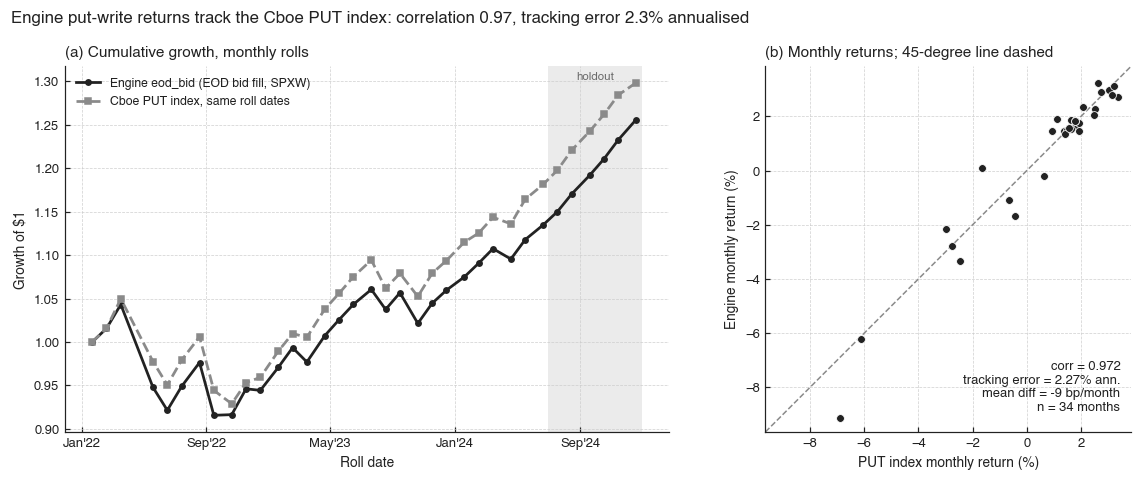

In [6]:
f2 = pd.read_csv(RES / 'f2_monthly.csv'); f2 = f2[f2.variant == 'eod_bid'].reset_index(drop=True)
put = pd.read_csv(W / 'external' / 'PUT_History.csv'); put['d'] = pd.to_datetime(put.DATE, format='%m/%d/%Y'); put = put.sort_values('d').set_index('d').PUT
def lvl(d):
    t = pd.Timestamp(str(int(d))); return put[:t].iloc[-1], put[:t].index[-1]
li = [lvl(d) for d in f2.date_in]; lo = [lvl(d) for d in f2.date_out]
f2['put_ret'] = [o[0] / i[0] - 1 for i, o in zip(li, lo)]
f2['lag_in'] = [(pd.Timestamp(str(int(d))) - i[1]).days for d, i in zip(f2.date_in, li)]
f2['lag_out'] = [(pd.Timestamp(str(int(d))) - o[1]).days for d, o in zip(f2.date_out, lo)]
corr = f2.ret.corr(f2.put_ret); te = (f2.ret - f2.put_ret).std(ddof=1) * np.sqrt(12); mean_diff = (f2.ret - f2.put_ret).mean()
x0 = todt(f2.date_in).iloc[0]
tl = pd.concat([pd.Series([x0]), todt(f2.date_out)]).reset_index(drop=True)
g_e = np.r_[1, (1 + f2.ret).cumprod()]; g_p = np.r_[1, (1 + f2.put_ret).cumprod()]
fig, (a, b) = plt.subplots(1, 2, figsize=(10.8, 4.4), gridspec_kw=dict(width_ratios=[1.35, 1]))
a.plot(tl, g_e, color=COL['F2'], lw=1.8, marker='o', ms=3.5, label='Engine eod_bid (EOD bid fill, SPXW)')
a.plot(tl, g_p, color='#8a8a8a', lw=1.8, ls='--', marker='s', ms=3.5, label='Cboe PUT index, same roll dates')
shade(a); a.xaxis.set_major_locator(mdates.MonthLocator(interval=8)); a.xaxis.set_major_formatter(mdates.DateFormatter("%b'%y")); a.set_ylabel('Growth of $1'); a.set_xlabel('Roll date'); a.legend(loc='upper left'); a.set_title('(a) Cumulative growth, monthly rolls')
b.scatter(f2.put_ret * 100, f2.ret * 100, color=COL['F2'], s=26, zorder=3, edgecolor='white', lw=.5)
lim = [min(f2.ret.min(), f2.put_ret.min()) * 100 - .5, max(f2.ret.max(), f2.put_ret.max()) * 100 + .5]
b.plot(lim, lim, color='#8a8a8a', lw=1, ls='--', zorder=2); b.set_xlim(lim); b.set_ylim(lim); b.set_aspect('equal')
b.set_xlabel('PUT index monthly return (%)'); b.set_ylabel('Engine monthly return (%)')
b.text(.97, .05, f'corr = {corr:.3f}\ntracking error = {te*100:.2f}% ann.\nmean diff = {mean_diff*1e4:.0f} bp/month\nn = {len(f2)} months', transform=b.transAxes, va='bottom', ha='right', fontsize=8.5)
b.set_title('(b) Monthly returns; 45-degree line dashed')
fig.suptitle(f'Engine put-write returns track the Cboe PUT index: correlation {corr:.2f}, tracking error {te*100:.1f}% annualised', x=.01, ha='left', fontsize=11)
fig.tight_layout(); save(fig, 'fig03_putwrite_validation.png')


In [7]:
say('fig03_putwrite_validation.png', f'Over {len(f2)} monthly rolls ({f2.date_in.iloc[0]} to {f2.date_out.iloc[-1]}): correlation {corr:.3f}, tracking error {te*100:.2f}% annualised (std of monthly difference x sqrt(12)), mean monthly difference engine minus PUT {mean_diff*1e4:.0f} bp. Terminal growth of $1: engine {g_e[-1]:.3f}, PUT {g_p[-1]:.3f}. Engine returns are premium minus put payoff over strike collateral with collateral and premium compounded at the 1-month T-bill rate (as in the PUT methodology); the PUT index uses AM settlement and a VWAP sale window (AM settlement, VWAP sale), so a level gap is expected.',
    f'Max calendar-day gap between a roll date and the last available PUT level: entry {f2.lag_in.max()}d, exit {f2.lag_out.max()}d.')

Over 34 monthly rolls (20220121 to 20241220): correlation 0.972, tracking error 2.27% annualised (std of monthly difference x sqrt(12)), mean monthly difference engine minus PUT -9 bp. Terminal growth of $1: engine 1.256, PUT 1.298. Engine returns are premium minus put payoff over strike collateral with collateral and premium compounded at the 1-month T-bill rate (as in the PUT methodology); the PUT index uses AM settlement and a VWAP sale window (AM settlement, VWAP sale), so a level gap is expected.

*Data check:* Max calendar-day gap between a roll date and the last available PUT level: entry 0d, exit 0d.

## 4. Equity curves of the primaries

**Figure 4 message:** after costs only H3 and H4 earn a positive cumulative excess return over 2022-2024; H1, H2 (A1), H5 (A4) lose and H6 is roughly flat.

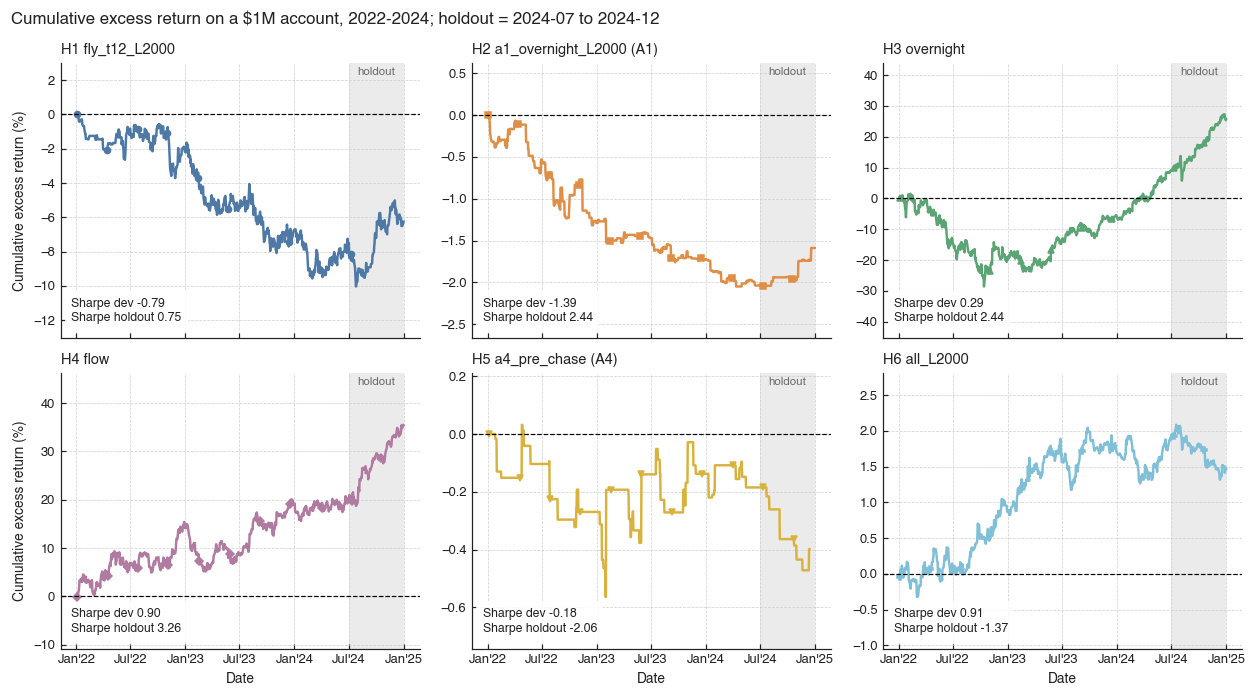

In [8]:
panels = [('H1','h1','fly_t12_L2000','H1 fly_t12_L2000'), ('H2','h2','a1_overnight_L2000','H2 a1_overnight_L2000 (A1)'),
          ('H3','h3','overnight','H3 overnight'), ('H4','h4','flow','H4 flow'),
          ('H5','h5','a4_pre_chase','H5 a4_pre_chase (A4)'), ('H6','h6','all_L2000','H6 all_L2000')]
fig, axs = plt.subplots(2, 3, figsize=(11.5, 6.4), sharex=True)
for ax, (fam, h, v, lab) in zip(axs.ravel(), panels):
    d = analysis.daily(h); d = d[d.variant == v].sort_values('date'); x = todt(d.date)
    ax.plot(x, (1 + d.ret).cumprod() * 100 - 100, color=COL[fam], lw=1.6, marker=rs.STRAT_MARK[fam], markevery=70, ms=4); shade(ax); ax.axhline(0, color='k', lw=.8, ls='--')
    s = {p: SC[(SC.strategy == h) & (SC.variant == v) & (SC.period == p)].sharpe for p in ('dev','holdout')}
    f = lambda z: 'n/a' if len(z) == 0 or not np.isfinite(z.iloc[0]) else f'{z.iloc[0]:.2f}'
    ax.margins(y=.3); ax.text(.03, .05, f"Sharpe dev {f(s['dev'])}\nSharpe holdout {f(s['holdout'])}", transform=ax.transAxes, va='bottom', fontsize=8,
            bbox=dict(fc='white', ec='none', alpha=.85)); ax.set_title(lab, fontsize=9.5)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b'%y")); ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
for ax in axs[:, 0]: ax.set_ylabel('Cumulative excess return (%)')
for ax in axs[1]: ax.set_xlabel('Date')
fig.suptitle('Cumulative excess return on a $1M account, 2022-2024; holdout = 2024-07 to 2024-12', x=.01, ha='left', fontsize=11)
fig.tight_layout(); save(fig, 'fig04_equity_curves.png')


In [9]:
fin = []
for fam, h, v, lab in panels:
    d = analysis.daily(h); d = d[d.variant == v].sort_values('date'); fin.append(f"{lab}: {((1+d.ret).prod()-1)*100:.1f}% total")
say('fig04_equity_curves.png', 'Terminal cumulative excess return over 2022-2024 (dev + holdout) -- ' + '; '.join(fin) + '. Per-panel dev/holdout Sharpe are annotated from `scorecard_daily.csv`.',
    'H2 and H5 panels use the A1/A4 variants because the original primaries have 10 and 1 fills.')

Terminal cumulative excess return over 2022-2024 (dev + holdout) -- H1 fly_t12_L2000: -6.3% total; H2 a1_overnight_L2000 (A1): -1.6% total; H3 overnight: 25.6% total; H4 flow: 35.4% total; H5 a4_pre_chase (A4): -0.4% total; H6 all_L2000: 1.5% total. Per-panel dev/holdout Sharpe are annotated from `scorecard_daily.csv`.

*Data check:* H2 and H5 panels use the A1/A4 variants because the original primaries have 10 and 1 fills.

## 5. H1 entry-time and latency sensitivity

**Figure 5 message:** for a short 0DTE iron fly, mean return per trade is below zero at 10:00 to 14:00 entries and every 95% interval includes zero; a few days dominate holdout P&L.

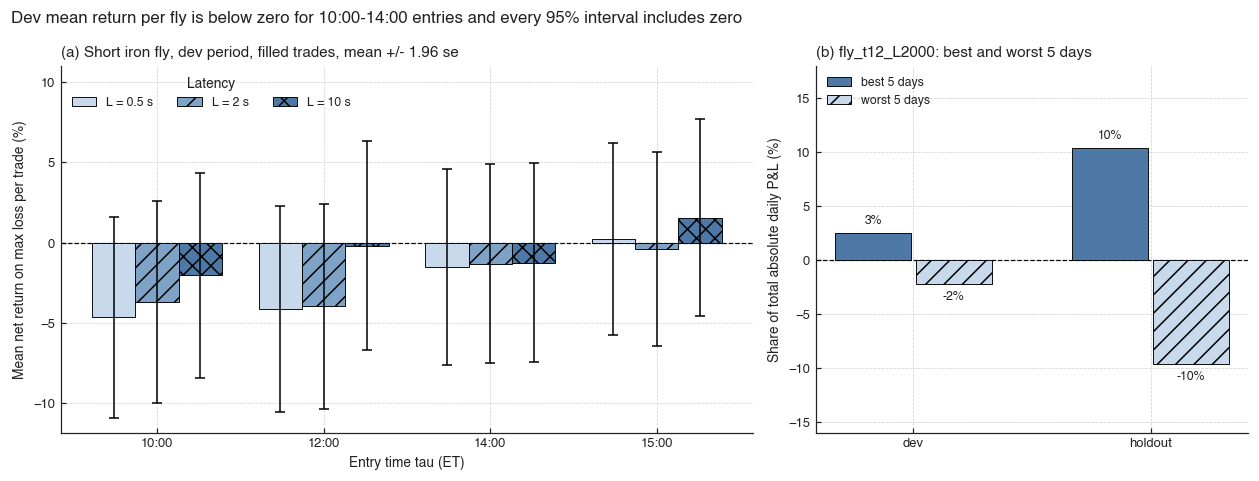

In [10]:
t1 = analysis.trades('h1'); t1 = t1[(t1.status == 'filled') & (t1.period == 'dev')]
rows = []
for tau in (10, 12, 14, 15):
    for lat in (500, 2000, 10000):
        x = t1[t1.variant == f'fly_t{tau}_L{lat}'].ret_on_risk.dropna()
        rows.append((tau, lat, len(x), x.mean(), 1.96 * x.std(ddof=1) / np.sqrt(len(x))))
r5 = pd.DataFrame(rows, columns=['tau','lat','n','m','ci'])
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw=dict(width_ratios=[1.6, 1]))
sh = {500: '#C7D9EA', 2000: '#7FA3C7', 10000: '#4E79A7'}; ht = {500: '', 2000: '//', 10000: 'xx'}; w = .26
for k, lat in enumerate((500, 2000, 10000)):
    q = r5[r5.lat == lat]; xs = np.arange(4) + (k - 1) * w
    a.bar(xs, q.m * 100, w, yerr=q.ci * 100, color=sh[lat], hatch=ht[lat], edgecolor='k', lw=.6, capsize=3, error_kw=dict(lw=1, ecolor='k', capthick=1), label=f'L = {lat/1000:g} s', zorder=3)
a.axhline(0, color='k', lw=.8, ls='--'); a.set_xticks(range(4)); a.set_xticklabels(['10:00','12:00','14:00','15:00']); a.set_xlabel('Entry time tau (ET)')
a.set_ylabel('Mean net return on max loss per trade (%)'); a.legend(title='Latency', loc='upper left', ncol=3)
a.set_ylim(top=11); a.set_title('(a) Short iron fly, dev period, filled trades, mean +/- 1.96 se')
dd = analysis.daily('h1'); dd = dd[dd.variant == 'fly_t12_L2000']
sh5 = {}
for per, g in dd.groupby('period'):
    p = g.pnl.sort_values(); tot = g.pnl.abs().sum()
    sh5[per] = (p.iloc[-5:].sum() / tot * 100, p.iloc[:5].sum() / tot * 100)
xs = np.arange(2)
for j, per in enumerate(('dev','holdout')):
    b.bar(j - .17, sh5[per][0], .32, color=COL['H1'], edgecolor='k', lw=.6, label='best 5 days' if j == 0 else None, zorder=3)
    b.bar(j + .17, sh5[per][1], .32, color='#C7D9EA', hatch='//', edgecolor='k', lw=.6, label='worst 5 days' if j == 0 else None, zorder=3)
    for o, v in ((-.17, sh5[per][0]), (.17, sh5[per][1])): b.text(j + o, v + (.6 if v > 0 else -.6), f'{v:.0f}%', ha='center', va='bottom' if v > 0 else 'top', fontsize=8)
b.axhline(0, color='k', lw=.8, ls='--'); b.set_xticks(xs); b.set_xticklabels(['dev','holdout']); b.set_ylim(-16, 18); b.legend(loc='upper left')
b.set_ylabel('Share of total absolute daily P&L (%)'); b.set_title('(b) fly_t12_L2000: best and worst 5 days')
fig.suptitle('Dev mean return per fly is below zero for 10:00-14:00 entries and every 95% interval includes zero', x=.01, ha='left', fontsize=11)
fig.tight_layout(); save(fig, 'fig05_h1_entry_latency.png')


In [11]:
neg = r5[r5.m + r5.ci < 0]
say('fig05_h1_entry_latency.png', 'Dev mean return on max loss per trade (%), 95% interval: ' + '; '.join(f"{int(r.tau)}h L{int(r.lat)}: {r.m*100:.1f} [{(r.m-r.ci)*100:.1f}, {(r.m+r.ci)*100:.1f}] (n={int(r.n)})" for r in r5.itertuples())
    + f". fly_t12_L2000 best-5 / worst-5 days as share of total |P&L|: dev {sh5['dev'][0]:.0f}% / {sh5['dev'][1]:.0f}%, holdout {sh5['holdout'][0]:.0f}% / {sh5['holdout'][1]:.0f}%.",
    'Intervals treat trades as independent (one trade per day, so no date clustering is applied); only `status == filled` rows used.')

Dev mean return on max loss per trade (%), 95% interval: 10h L500: -4.6 [-10.9, 1.6] (n=532); 10h L2000: -3.7 [-10.0, 2.6] (n=532); 10h L10000: -2.0 [-8.4, 4.4] (n=530); 12h L500: -4.1 [-10.5, 2.3] (n=472); 12h L2000: -4.0 [-10.3, 2.4] (n=471); 12h L10000: -0.2 [-6.7, 6.3] (n=463); 14h L500: -1.5 [-7.6, 4.6] (n=505); 14h L2000: -1.3 [-7.5, 4.9] (n=496); 14h L10000: -1.2 [-7.4, 5.0] (n=490); 15h L500: 0.2 [-5.7, 6.2] (n=536); 15h L2000: -0.4 [-6.4, 5.6] (n=529); 15h L10000: 1.5 [-4.6, 7.7] (n=515). fly_t12_L2000 best-5 / worst-5 days as share of total |P&L|: dev 3% / -2%, holdout 10% / -10%.

*Data check:* Intervals treat trades as independent (one trade per day, so no date clustering is applied); only `status == filled` rows used.

## 6. H2 overnight vs intraday: where the P&L goes

In [12]:
eh = pd.concat([pd.read_csv(f, usecols=['tau','lat','root','date','exp','k','cp','bid','ask','ms']) for f in sorted(glob.glob(str(EXT / 'h2_etf_*.csv')))])
eh = eh[eh.lat.isin([2000, 99999])].sort_values('ms').drop_duplicates(['tau','lat','root','date','exp','k','cp'])
eh['mid'] = (eh.bid + eh.ask) / 2
q = eh.set_index(['tau','lat','root','date','exp','k','cp'])[['bid','ask','mid']]
t2 = analysis.trades('h2'); t2 = t2[t2.variant.isin(['a1_overnight_L2000','a1_intraday_L2000']) & t2.status.str.startswith('filled') & (t2.period == 'dev')].copy()
t2['ov'] = t2.variant.str.contains('overnight')
ENT = dict(ov=57480000, intra=34380000); EXI = dict(ov=34380000, intra=57480000)
def look(df, tau_col, date_col, lat_col):
    out = {}
    for cp in 'CP':
        idx = pd.MultiIndex.from_arrays([df[tau_col], df[lat_col], df.root, df[date_col], df.exp, df.k, [cp] * len(df)])
        r = q.reindex(idx); out[cp] = r.reset_index(drop=True)
    return out
t2 = t2.reset_index(drop=True)
t2['tau0'] = np.where(t2.ov, ENT['ov'], ENT['intra']); t2['tau1'] = np.where(t2.ov, EXI['ov'], EXI['intra'])
t2['lat0'] = 2000; t2['lat1'] = np.where(t2.status.str.contains('chase'), 99999, 2000)
e = look(t2, 'tau0', 'd0', 'lat0'); x = look(t2, 'tau1', 'd1', 'lat1')
t2['mid0'] = e['C'].mid + e['P'].mid; t2['mid1'] = x['C'].mid + x['P'].mid
t2['bid0'] = e['C'].bid + e['P'].bid; t2['ask1'] = x['C'].ask + x['P'].ask
t2['found'] = t2[['mid0','mid1']].notna().all(axis=1)
t2['mid_pnl'] = t2.n * 100 * (t2.mid0 - t2.mid1)
t2['spread'] = t2.opt_pnl - t2.mid_pnl
den = t2.n * 100 * t2.premium
for c, src in (('c_mid', t2.mid_pnl), ('c_spread', t2.spread), ('c_hedge', t2.hedge_pnl), ('c_fees', -t2.fees), ('c_total', t2.pnl)): t2[c] = src / den * 100
chk = {}
chk['quotes_found'] = f"{t2.found.mean():.1%} of {len(t2)} trades"
chk['entry_fill_eq_sum_of_bids'] = f"{(abs(t2.opt_entry - t2.bid0) < 1e-6).mean():.1%}"
chk['exit_fill_eq_sum_of_asks'] = f"{(abs(t2.opt_exit - t2.ask1) < 1e-6).mean():.1%}"
f = t2[t2.found]
chk['mid+spread-opt_pnl max abs'] = abs(f.mid_pnl + f.spread - f.opt_pnl).max()
chk['opt+hedge-fees-pnl max abs ($)'] = abs(f.opt_pnl + f.hedge_pnl - f.fees - f.pnl).max()
chk['components-sum minus pnl max abs (% prem)'] = abs(f.c_mid + f.c_spread + f.c_hedge + f.c_fees - f.c_total).max()
chk['spread_cost_from_quotes_vs_residual max abs ($)'] = abs(f.n * 100 * ((f.bid0 - f.mid0) + (f.mid1 - f.ask1)) - f.spread).max()
print(pd.Series(chk).to_string())

quotes_found                                       100.0% of 770 trades
entry_fill_eq_sum_of_bids                                        100.0%
exit_fill_eq_sum_of_asks                                         100.0%
mid+spread-opt_pnl max abs                                          0.0
opt+hedge-fees-pnl max abs ($)                                    0.005
components-sum minus pnl max abs (% prem)                      0.000084
spread_cost_from_quotes_vs_residual max abs ($)                     0.0


**Figure 6 message:** spread cost is about -0.77% of premium both overnight and intraday, so the difference in net P&L (-1.25% vs +0.14%) comes from mid-to-mid option P&L (0.18% vs 1.58%).

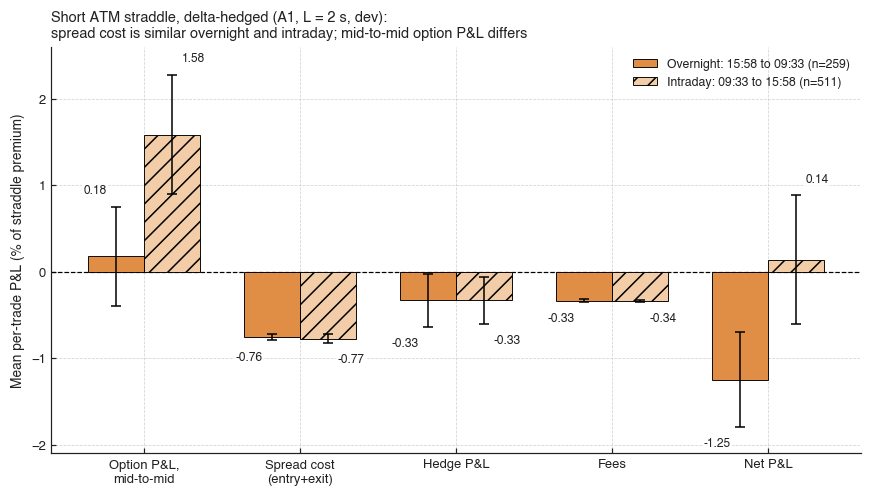

In [13]:
comp = [('c_mid','Option P&L,\nmid-to-mid'), ('c_spread','Spread cost\n(entry+exit)'), ('c_hedge','Hedge P&L'), ('c_fees','Fees'), ('c_total','Net P&L')]
fig, ax = plt.subplots(figsize=(9.5, 4.8)); w = .36; res6 = {}
for k, (lab, ov, colr, hat) in enumerate((('Overnight: 15:58 to 09:33', True, COL['H2'], ''), ('Intraday: 09:33 to 15:58', False, '#F3CDA8', '//'))):
    g = f[f.ov == ov]; m = [g[c].mean() for c, _ in comp]; ci = [1.96 * g[c].std(ddof=1) / np.sqrt(len(g)) for c, _ in comp]
    res6[lab] = dict(zip([c for c, _ in comp], m)); res6[lab]['n'] = len(g)
    xs = np.arange(len(comp)) + (k - .5) * w
    ax.bar(xs, m, w, yerr=ci, color=colr, hatch=hat, capsize=3, error_kw=dict(lw=1, ecolor='k', capthick=1), label=f'{lab} (n={len(g)})', edgecolor='k', lw=.6, zorder=3)
    for xx, mm, cc in zip(xs, m, ci): ax.text(xx + (-.06 if ov else .06), (mm + cc + .12) if mm >= 0 else (mm - cc - .12), f'{mm:.2f}', ha='right' if ov else 'left', va='bottom' if mm >= 0 else 'top', fontsize=7.8, zorder=6, bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=.85))
ax.axhline(0, color='k', lw=.8, ls='--'); ax.set_xticks(range(len(comp))); ax.set_xticklabels([l for _, l in comp])
ax.set_ylabel('Mean per-trade P&L (% of straddle premium)'); ax.set_ylim(-2.1, 2.6); ax.legend(loc='upper right')
ax.set_title('Short ATM straddle, delta-hedged (A1, L = 2 s, dev):\nspread cost is similar overnight and intraday; mid-to-mid option P&L differs', loc='left', fontsize=9.5)
save(fig, 'fig06_h2_decomposition.png')


In [14]:
tbl = pd.DataFrame(res6).T[['c_mid','c_spread','c_hedge','c_fees','c_total','n']]
display(tbl.round(3))
say('fig06_h2_decomposition.png', 'Mean % of premium per trade (dev, A1, L=2s), overnight vs intraday: ' + '; '.join(
    f"{k.split(':')[0]} (n={int(v['n'])}) mid {v['c_mid']:.2f}, spread {v['c_spread']:.2f}, hedge {v['c_hedge']:.2f}, fees {v['c_fees']:.2f}, net {v['c_total']:.2f}" for k, v in res6.items()) + '.',
    '; '.join(f'{k}: {v}' if isinstance(v, str) else f'{k}: {v:.2e}' for k, v in chk.items()) + '. Note: opt_pnl - mid P&L defines spread cost, so that identity is exact by construction; the independent checks are the fill-equals-bid/ask match rates and the quote-based spread recomputation.')

,c_mid,c_spread,c_hedge,c_fees,c_total,n
Overnight: 15:58 to 09:33,0.176,-0.757,-0.333,-0.335,-1.248,259.0
Intraday: 09:33 to 15:58,1.584,-0.774,-0.334,-0.338,0.137,511.0


Mean % of premium per trade (dev, A1, L=2s), overnight vs intraday: Overnight (n=259) mid 0.18, spread -0.76, hedge -0.33, fees -0.33, net -1.25; Intraday (n=511) mid 1.58, spread -0.77, hedge -0.33, fees -0.34, net 0.14.

*Data check:* quotes_found: 100.0% of 770 trades; entry_fill_eq_sum_of_bids: 100.0%; exit_fill_eq_sum_of_asks: 100.0%; mid+spread-opt_pnl max abs: 2.84e-14; opt+hedge-fees-pnl max abs ($): 5.00e-03; components-sum minus pnl max abs (% prem): 8.41e-05; spread_cost_from_quotes_vs_residual max abs ($): 1.15e-11. Note: opt_pnl - mid P&L defines spread cost, so that identity is exact by construction; the independent checks are the fill-equals-bid/ask match rates and the quote-based spread recomputation.

## 7. H3 overnight vs intraday equity drift

**Figure 7 message:** over 2022-2024 the intraday leg and the overnight leg of equal-weight 16-symbol books both earn positive cumulative excess returns (25.6% overnight, 32.3% intraday).

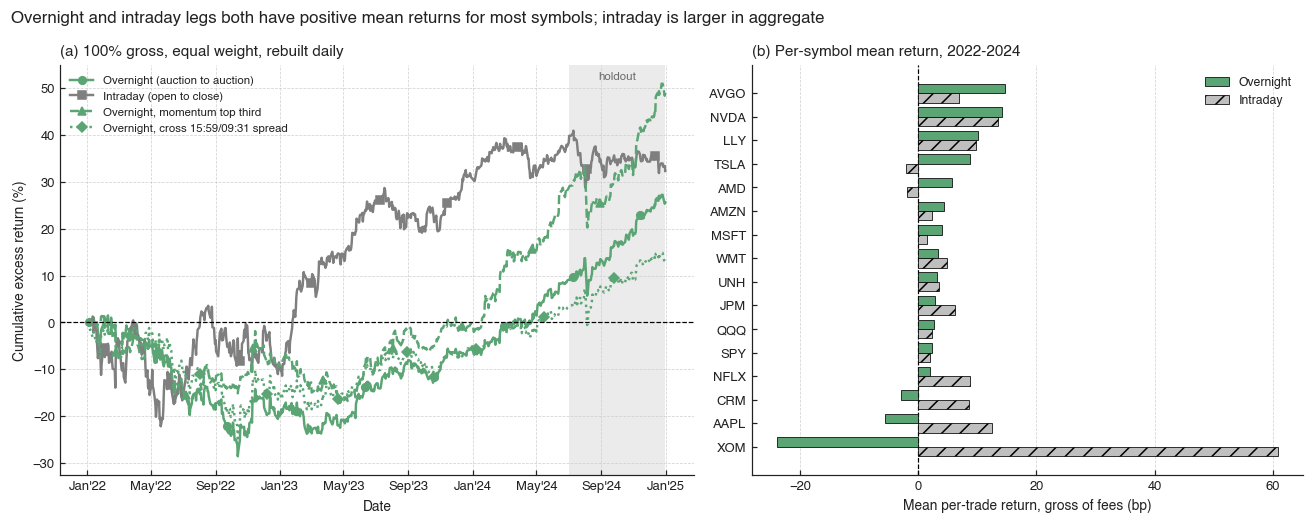

In [15]:
vs = [('overnight','Overnight (auction to auction)', COL['H3'], '-', 'o'), ('intraday','Intraday (open to close)', '#7F7F7F', '-', 's'),
      ('overnight_mom','Overnight, momentum top third', COL['H3'], '--', '^'), ('overnight_cross_spread','Overnight, cross 15:59/09:31 spread', COL['H3'], ':', 'D')]
d3 = analysis.daily('h3')
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw=dict(width_ratios=[1.15, 1]))
fin3 = {}
for i, (v, lab, c, l, m_) in enumerate(vs):
    d = d3[d3.variant == v].sort_values('date'); cum = ((1 + d.ret).cumprod() - 1) * 100; fin3[v] = cum.iloc[-1]
    a.plot(todt(d.date), cum, color=c, ls=l, lw=1.6, marker=m_, markevery=(i * 18, 90), ms=5, label=lab)
shade(a); a.axhline(0, color='k', lw=.8, ls='--'); a.legend(loc='upper left', fontsize=7.5); a.set_ylabel('Cumulative excess return (%)'); a.set_xlabel('Date')
a.set_title('(a) 100% gross, equal weight, rebuilt daily'); a.xaxis.set_major_formatter(mdates.DateFormatter("%b'%y"))
t3 = pd.read_csv(RES / 'h3_trades.csv'); t3 = t3[t3.variant.isin(['overnight','intraday'])]
ps = t3.groupby(['sym','variant']).ret.mean().unstack() * 1e4; ps = ps.sort_values('overnight')
ys = np.arange(len(ps)); b.barh(ys + .2, ps.overnight, .4, color=COL['H3'], edgecolor='k', lw=.5, label='Overnight', zorder=3); b.barh(ys - .2, ps.intraday, .4, color='#BFBFBF', hatch='//', edgecolor='k', lw=.5, label='Intraday', zorder=3)
b.set_yticks(ys); b.set_yticklabels(ps.index); b.axvline(0, color='k', lw=.8, ls='--'); b.set_xlabel('Mean per-trade return, gross of fees (bp)'); b.legend(loc='upper right'); b.grid(axis='y', visible=False)
b.set_title('(b) Per-symbol mean return, 2022-2024')
fig.suptitle('Overnight and intraday legs both have positive mean returns for most symbols; intraday is larger in aggregate', x=.01, ha='left', fontsize=11)
fig.tight_layout(); save(fig, 'fig07_h3_overnight_intraday.png')


In [16]:
npos_o = (ps.overnight > 0).sum(); npos_i = (ps.intraday > 0).sum()
say('fig07_h3_overnight_intraday.png', 'Terminal cumulative excess return: ' + '; '.join(f"{lab} {fin3[v]:.1f}%" for v, lab, *_ in vs) + f'. Mean overnight return is positive for {npos_o} of {len(ps)} symbols and mean intraday return for {npos_i} of {len(ps)}; pooled mean overnight {t3[t3.variant=="overnight"].ret.mean()*1e4:.1f} bp vs intraday {t3[t3.variant=="intraday"].ret.mean()*1e4:.1f} bp per trade.',
    "Per-symbol bars use the `ret` column of h3_trades (per-name return for the leg, before the `fees` column); full 2022-2024 sample.")

Terminal cumulative excess return: Overnight (auction to auction) 25.6%; Intraday (open to close) 32.3%; Overnight, momentum top third 48.9%; Overnight, cross 15:59/09:31 spread 12.9%. Mean overnight return is positive for 13 of 16 symbols and mean intraday return for 14 of 16; pooled mean overnight 4.3 bp vs intraday 5.0 bp per trade.

*Data check:* Per-symbol bars use the `ret` column of h3_trades (per-name return for the leg, before the `fees` column); full 2022-2024 sample.

## 8. H4 Fama-MacBeth and long-short curves

**Figure 8 message:** the flow signal has a positive Fama-MacBeth slope in both periods, and only the holdout flow slope has a 95% interval that excludes zero.

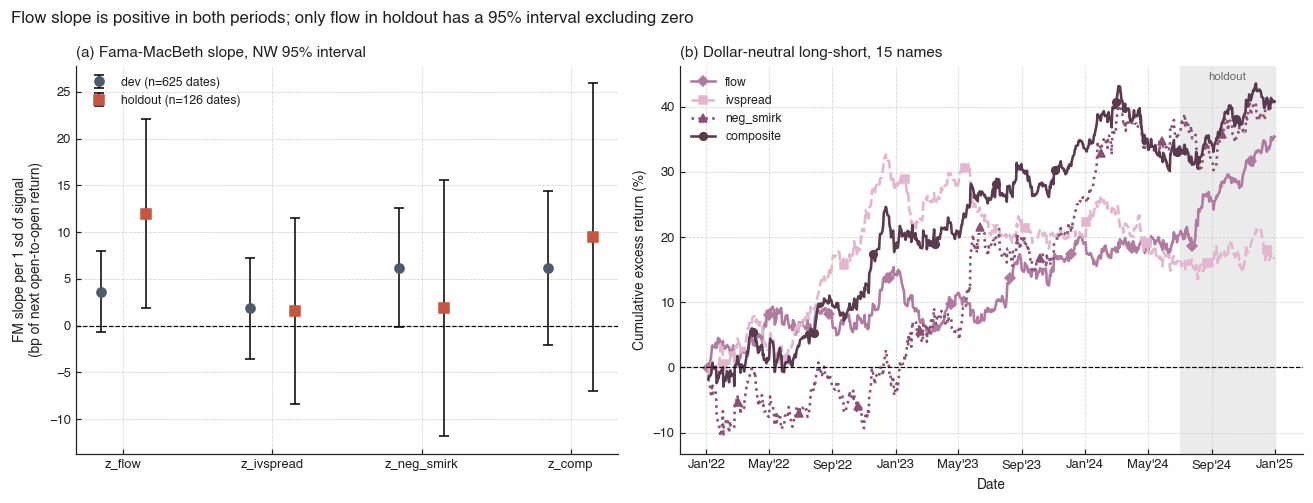

In [17]:
fm = pd.read_csv(RES / 'scorecard_h4_fm.csv'); sigs = ['z_flow','z_ivspread','z_neg_smirk','z_comp']
fm['ci'] = 1.96 * (fm.mean_slope / fm.nw_t).abs()
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw=dict(width_ratios=[1, 1.15]))
for k, (per, c, m_) in enumerate((('dev', DEV_COL, 'o'), ('holdout', HOLD_COL, 's'))):
    g = fm[fm.period == per].set_index('signal').loc[sigs]; xs = np.arange(4) + (k - .5) * .3
    a.errorbar(xs, g.mean_slope * 1e4, yerr=g.ci * 1e4, fmt=m_, color=c, ecolor='k', capsize=3, capthick=1, elinewidth=1, ms=6, label=f'{per} (n={int(g.n_dates.iloc[0])} dates)', zorder=3)
a.axhline(0, color='k', lw=.8, ls='--'); a.set_xticks(range(4)); a.set_xticklabels(sigs); a.set_ylabel('FM slope per 1 sd of signal\n(bp of next open-to-open return)')
a.legend(loc='upper left'); a.set_title('(a) Fama-MacBeth slope, NW 95% interval')
c4 = {'flow': COL['H4'], 'composite': '#5A3A4F', 'ivspread': '#E3B5CE', 'neg_smirk': '#8C4F75'}; ls4 = {'flow': '-', 'composite': '-', 'ivspread': '--', 'neg_smirk': ':'}
m4 = {'flow': 'D', 'composite': 'o', 'ivspread': 's', 'neg_smirk': '^'}
d4 = analysis.daily('h4'); fin4 = {}
for i, v in enumerate(('flow','ivspread','neg_smirk','composite')):
    d = d4[d4.variant == v].sort_values('date'); cum = ((1 + d.ret).cumprod() - 1) * 100; fin4[v] = cum.iloc[-1]
    b.plot(todt(d.date), cum, color=c4[v], ls=ls4[v], lw=1.7, marker=m4[v], markevery=(i * 20, 80), ms=5, label=v)
shade(b); b.axhline(0, color='k', lw=.8, ls='--'); b.legend(loc='upper left'); b.set_ylabel('Cumulative excess return (%)'); b.set_xlabel('Date')
b.set_title('(b) Dollar-neutral long-short, 15 names'); b.xaxis.set_major_formatter(mdates.DateFormatter("%b'%y"))
fig.suptitle('Flow slope is positive in both periods; only flow in holdout has a 95% interval excluding zero', x=.01, ha='left', fontsize=11)
fig.tight_layout(); save(fig, 'fig08_h4_fama_macbeth.png')


In [18]:
say('fig08_h4_fama_macbeth.png', 'FM slope (bp per 1 sd), NW t: ' + '; '.join(f"{r.signal} {r.period} {r.mean_slope*1e4:.1f} (t={r.nw_t:.2f})" for r in fm.itertuples())
    + '. Terminal cumulative excess return: ' + ', '.join(f'{k} {v:.1f}%' for k, v in fin4.items()) + '.',
    'CI half-width = 1.96 x |slope / t| as specified; n dates 625 (dev) and 126 (holdout) for every signal.')

FM slope (bp per 1 sd), NW t: z_flow dev 3.6 (t=1.63); z_ivspread dev 1.9 (t=0.67); z_neg_smirk dev 6.2 (t=1.93); z_comp dev 6.2 (t=1.47); z_flow holdout 12.0 (t=2.32); z_ivspread holdout 1.6 (t=0.31); z_neg_smirk holdout 1.9 (t=0.27); z_comp holdout 9.5 (t=1.13). Terminal cumulative excess return: flow 35.4%, ivspread 16.9%, neg_smirk 40.5%, composite 40.8%.

*Data check:* CI half-width = 1.96 x |slope / t| as specified; n dates 625 (dev) and 126 (holdout) for every signal.

## 9. H5 event returns (exploratory A4 variants)

**Figure 9 message:** the filled A4 straddle events are few (11 and 2 in holdout), so period means for the sell-before and hold-through designs rest on small samples.

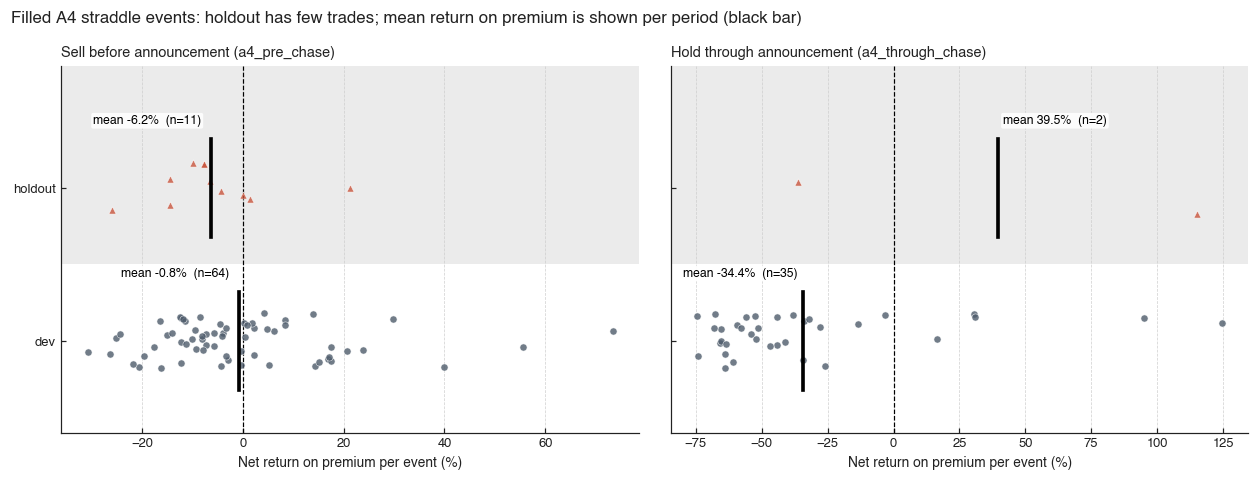

In [19]:
t5 = analysis.trades('h5'); t5 = t5[t5.variant.isin(['a4_pre_chase','a4_through_chase']) & t5.status.str.startswith('filled')]
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.4), sharey=True); rng = np.random.default_rng(0); st5 = {}
for ax, v, lab in zip(axs, ('a4_pre_chase','a4_through_chase'), ('Sell before announcement (a4_pre_chase)', 'Hold through announcement (a4_through_chase)')):
    g = t5[t5.variant == v]
    for j, (per, c, m_) in enumerate((('dev', DEV_COL, 'o'), ('holdout', HOLD_COL, '^'))):
        x = g[g.period == per].ret_on_premium * 100
        ax.scatter(x, j + rng.uniform(-.18, .18, len(x)), s=22, marker=m_, color=c, alpha=.8, edgecolor='white', lw=.4, zorder=3)
        if len(x):
            ax.plot([x.mean()] * 2, [j - .32, j + .32], color='k', lw=2.4, zorder=4); mu = x.mean(); ax.text((min(mu, 0) - 2) if mu < 0 else (max(mu, 0) + 2), j + .44, f'mean {mu:.1f}%  (n={len(x)})', ha='right' if mu < 0 else 'left', va='center', fontsize=8, color='k', bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=.9), zorder=6)
        st5[(v, per)] = (len(x), x.mean() if len(x) else np.nan, x.median() if len(x) else np.nan)
    ax.axvline(0, color='k', lw=.8, ls='--'); ax.set_yticks([0, 1]); ax.set_yticklabels(['dev', 'holdout']); ax.set_ylim(-.6, 1.8)
    ax.axhspan(.5, 1.8, color=rs.TEST_BAND, zorder=0, lw=0)
    ax.set_xlabel('Net return on premium per event (%)'); ax.set_title(lab, fontsize=9.5); ax.grid(axis='y', visible=False)
fig.suptitle('Filled A4 straddle events: holdout has few trades; mean return on premium is shown per period (black bar)', x=.01, ha='left', fontsize=11)
fig.tight_layout(); save(fig, 'fig09_h5_events.png')


In [20]:
say('fig09_h5_events.png', 'Filled events (n, mean %, median %): ' + '; '.join(f"{v} {p}: n={n}, mean {m:.1f}, median {md_:.1f}" for (v, p), (n, m, md_) in st5.items()) + '. A4 is labelled exploratory in the pre-registration (slow-execution proxy).',
    "Period assigned by `d_out` (exit date) via analysis.trades; only statuses starting with 'filled'.")

Filled events (n, mean %, median %): a4_pre_chase dev: n=64, mean -0.8, median -4.3; a4_pre_chase holdout: n=11, mean -6.2, median -7.8; a4_through_chase dev: n=35, mean -34.4, median -51.3; a4_through_chase holdout: n=2, mean 39.5, median 39.5. A4 is labelled exploratory in the pre-registration (slow-execution proxy).

*Data check:* Period assigned by `d_out` (exit date) via analysis.trades; only statuses starting with 'filled'.

## 10. H6 sign-randomisation placebo

**Figure 10 message:** H6's dev P&L sits in the upper tail of 1,000 random-sign placebos (99th percentile), while holdout P&L is at the 24th percentile.

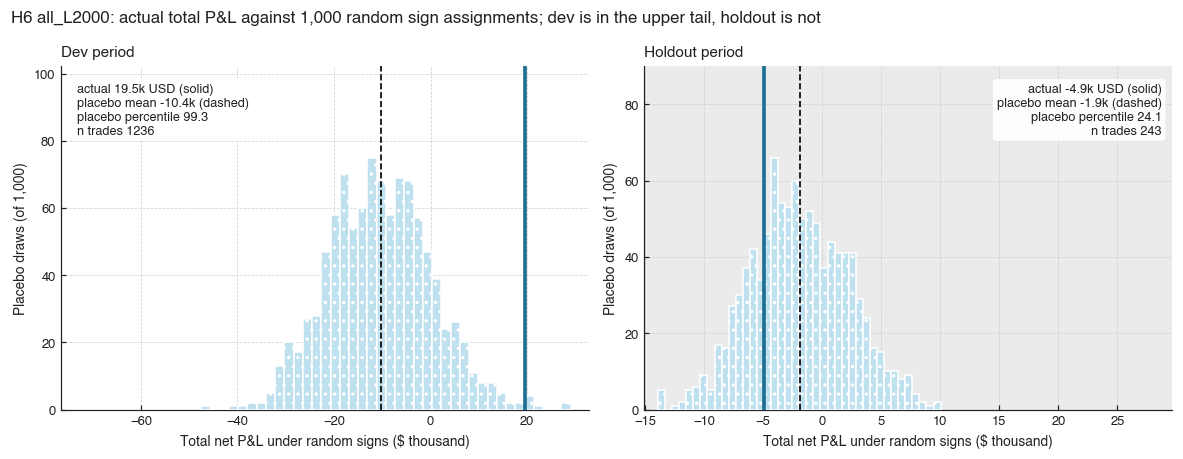

In [21]:
t6 = analysis.trades('h6'); t6 = t6[t6.variant == 'all_L2000'].reset_index(drop=True)
chk6 = abs(t6.pnl - (np.where(t6.side == 1, t6.long_pnl, t6.short_pnl) - t6.fees)).max()
rng = np.random.default_rng(0); S = rng.choice([1, -1], size=(1000, len(t6)))
pl = np.where(S == 1, (t6.long_pnl - t6.fees).values, (t6.short_pnl - t6.fees).values)
res10 = {}
fig, axs = plt.subplots(1, 2, figsize=(10.8, 4.2))
for ax, per in zip(axs, ('dev','holdout')):
    m = (t6.period == per).values; tot = pl[:, m].sum(1); act = t6.pnl[m].sum(); pct = (tot <= act).mean() * 100
    res10[per] = dict(actual=act, pct=pct, mean=tot.mean(), sd=tot.std(), n=int(m.sum()))
    ax.hist(tot / 1e3, bins=40, color='#BFE0EE', edgecolor='white', hatch='..', zorder=3)
    ax.axvline(act / 1e3, color=COL['H6'] if False else '#1F6F94', lw=2.4, zorder=4)
    ax.axvline(tot.mean() / 1e3, color='k', lw=1.1, ls='--', zorder=4)
    ax.set_ylim(top=ax.get_ylim()[1] * 1.3); xl0, xl1 = ax.get_xlim(); sp = xl1 - xl0
    ax.set_xlim((xl0 - .3 * sp, xl1) if per == 'dev' else (xl0, xl1 + .7 * sp))
    ax.text(.03 if per == 'dev' else .98, .95, f'actual {act/1e3:,.1f}k USD (solid)\nplacebo mean {tot.mean()/1e3:,.1f}k (dashed)\nplacebo percentile {pct:.1f}\nn trades {m.sum()}', transform=ax.transAxes, ha='left' if per == 'dev' else 'right', va='top', fontsize=8.3, zorder=6, bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='none', alpha=.95))
    if per == 'holdout': rs.shade_test(ax, *ax.get_xlim(), label=None, zorder=0)
    ax.set_xlabel('Total net P&L under random signs ($ thousand)'); ax.set_ylabel('Placebo draws (of 1,000)'); ax.set_title(f'{per.capitalize()} period')
fig.suptitle('H6 all_L2000: actual total P&L against 1,000 random sign assignments; dev is in the upper tail, holdout is not', x=.01, ha='left', fontsize=11)
fig.tight_layout(); save(fig, 'fig10_h6_placebo.png')


In [22]:
say('fig10_h6_placebo.png', ' '.join(f"{p}: actual total net P&L ${v['actual']:,.0f} (placebo mean ${v['mean']:,.0f}, sd ${v['sd']:,.0f}), placebo percentile {v['pct']:.1f} (share of placebo totals at or below actual), {v['n']} symbol-days." for p, v in res10.items()),
    f'Actual pnl reproduced from long_pnl/short_pnl/fees by side: max abs difference ${chk6:.4f} per trade. Placebo uses numpy default_rng(0), one +/-1 draw per trade.')

dev: actual total net P&L $19,516 (placebo mean $-10,367, sd $10,705), placebo percentile 99.3 (share of placebo totals at or below actual), 1236 symbol-days. holdout: actual total net P&L $-4,878 (placebo mean $-1,896, sd $4,152), placebo percentile 24.1 (share of placebo totals at or below actual), 243 symbol-days.

*Data check:* Actual pnl reproduced from long_pnl/short_pnl/fees by side: max abs difference $0.0050 per trade. Placebo uses numpy default_rng(0), one +/-1 draw per trade.

## 11. Decisions and primary scorecard

In [23]:
D = DEC.copy()
D['fills'] = D.fills.map(lambda v: '' if pd.isna(v) else f'{int(v)}')
def pc(v): return '' if pd.isna(v) else f'{v*100:.2f}%'
def nf(v, d=2): return '' if pd.isna(v) else f'{v:.{d}f}'
tab1 = '| strategy | variant | fills | verdict | dev ann | dev Sharpe | dev NW t | dev DSR | holdout ann | holdout Sharpe | RW p (dev) |\n|---|---|---|---|---|---|---|---|---|---|---|\n'
for r in D.itertuples(): tab1 += f'| {r.strategy} | {r.variant} | {r.fills} | {r.verdict} | {pc(r.dev_ann)} | {nf(r.dev_sharpe)} | {nf(r.dev_nw_t)} | {nf(r.dev_dsr,3)} | {pc(r.hold_ann)} | {nf(r.hold_sharpe)} | {nf(r.rw_p_dev,3)} |\n'
P = SC[SC.primary].sort_values(['strategy','variant','period'], key=lambda s: s.map({'dev':0,'holdout':1}) if s.name=='period' else s)
tab2 = '| strategy | variant | period | days | ann ret | Sharpe | NW t | max DD | DSR | RW p (dev) |\n|---|---|---|---|---|---|---|---|---|---|\n'
for r in P.itertuples(): tab2 += f'| {r.strategy} | {r.variant} | {r.period} | {int(r.days)} | {pc(r.ann_ret)} | {nf(r.sharpe)} | {nf(r.nw_t)} | {pc(r.max_dd)} | {nf(r.dsr,3)} | {nf(r.rw_p_dev,3)} |\n'
display(Markdown('### decisions.csv\n\n' + tab1 + '\n\n### Primary rows of scorecard_daily.csv\n\n' + tab2))

### decisions.csv

| strategy | variant | fills | verdict | dev ann | dev Sharpe | dev NW t | dev DSR | holdout ann | holdout Sharpe | RW p (dev) |
|---|---|---|---|---|---|---|---|---|---|---|
| h1 | fly_t12_L2000 | 581 | REJECT: dev mean<=0; dev ex-top5<=0 | -3.13% | -0.79 | -1.42 | 0.000 | 3.01% | 0.75 | 0.755 |
| h2 | overnight_L2000 | 10 | UNTESTABLE (fills=10) | -0.02% | -0.36 | -0.57 | 0.002 | 0.00% |  | 0.971 |
| h2 | a1_overnight_L2000 | 283 | REJECT: dev mean<=0; dev ex-top5<=0 | -0.83% | -1.39 | -2.22 | 0.000 | 0.89% | 2.44 | 0.397 |
| h3 | overnight |  | REJECT: dev ex-top5<=0 | 4.80% | 0.29 | 0.50 | 0.029 | 28.80% | 2.44 | 0.678 |
| h4 | flow |  | PASS (dev NW t=1.48) | 7.82% | 0.90 | 1.48 | 0.173 | 23.70% | 3.26 | 0.363 |
| h5 | pre_L2000 | 1 | UNTESTABLE (fills=1) | -0.04% | -0.64 | -1.00 | 0.000 | 0.00% |  | 0.903 |
| h5 | a4_pre_chase | 75 | REJECT: dev mean<=0; holdout mean<=0; dev ex-top5<=0 | -0.07% | -0.18 | -0.30 | 0.004 | -0.46% | -2.06 | 0.956 |
| h6 | all_L2000 |  | REJECT: holdout mean<=0 | 0.77% | 0.91 | 1.50 | 0.175 | -0.85% | -1.37 | 0.207 |


### Primary rows of scorecard_daily.csv

| strategy | variant | period | days | ann ret | Sharpe | NW t | max DD | DSR | RW p (dev) |
|---|---|---|---|---|---|---|---|---|---|
| h1 | fly_t12_L2000 | dev | 625 | -3.13% | -0.79 | -1.42 | -9.57% | 0.000 | 0.755 |
| h1 | fly_t12_L2000 | holdout | 128 | 3.01% | 0.75 | 0.50 | -2.75% |  | 0.755 |
| h2 | a1_overnight_L2000 | dev | 624 | -0.83% | -1.39 | -2.22 | -2.06% | 0.000 | 0.397 |
| h2 | a1_overnight_L2000 | holdout | 128 | 0.89% | 2.44 | 1.74 | -0.04% |  | 0.397 |
| h2 | overnight_L2000 | dev | 624 | -0.02% | -0.36 | -0.57 | -0.10% | 0.002 | 0.971 |
| h2 | overnight_L2000 | holdout | 128 | 0.00% |  |  | 0.00% |  | 0.971 |
| h3 | overnight | dev | 624 | 4.80% | 0.29 | 0.50 | -29.64% | 0.029 | 0.678 |
| h3 | overnight | holdout | 128 | 28.80% | 2.44 | 2.21 | -7.04% |  | 0.678 |
| h4 | flow | dev | 623 | 7.82% | 0.90 | 1.48 | -8.87% | 0.173 | 0.363 |
| h4 | flow | holdout | 128 | 23.70% | 3.26 | 2.29 | -2.34% |  | 0.363 |
| h5 | a4_pre_chase | dev | 622 | -0.07% | -0.18 | -0.30 | -0.60% | 0.004 | 0.956 |
| h5 | a4_pre_chase | holdout | 117 | -0.46% | -2.06 | -1.49 | -0.29% |  | 0.956 |
| h5 | pre_L2000 | dev | 622 | -0.04% | -0.64 | -1.00 | -0.10% | 0.000 | 0.903 |
| h5 | pre_L2000 | holdout | 117 | 0.00% |  |  | 0.00% |  | 0.903 |
| h6 | all_L2000 | dev | 624 | 0.77% | 0.91 | 1.50 | -0.76% | 0.175 | 0.207 |
| h6 | all_L2000 | holdout | 128 | -0.85% | -1.37 | -1.04 | -0.75% |  | 0.207 |


## Figure notes file

In [24]:
lines = ['# Wave-2 figure notes', '', 'Generated by `wave2/notebooks/wave2_report.ipynb`. Facts only; no interpretation beyond the numbers.', '']
for k in sorted(NOTES):
    t, c = NOTES[k]; lines.append(f'- **{k}**: {t}' + (f' *Data check:* {c}' if c else ''))
(FIG / 'figure_notes.md').write_text('\n'.join(lines) + '\n'); print(open(FIG / 'figure_notes.md').read()[:3000])

# Wave-2 figure notes

Generated by `wave2/notebooks/wave2_report.ipynb`. Facts only; no interpretation beyond the numbers.

- **fig01_fill_funnel.png**: Filled share by design (H3/H6 list only executed rows; H4 uses the `tradeable` flag): H1 fly_t12_L2000 (primary): 581 of 698 (83%) filled; H2 overnight_L2000 (primary): 10 of 1,466 (1%) filled; H2 a1_overnight_L2000 (A1): 283 of 1,466 (19%) filled; H3 overnight (primary): 10,434 of 10,434 (100%) filled; H4 flow (primary): 9,043 of 11,248 (80%) filled; H5 pre_L2000 (primary): 1 of 179 (1%) filled; H5 a1_pre_L2000 (A1): 9 of 179 (5%) filled; H5 a4_pre_chase (A4): 75 of 179 (42%) filled; H6 all_L2000 (primary): 1,479 of 1,479 (100%) filled.
- **fig02_cost_atlas.png**: Among cells with |K/S-1|<1%, n-weighted effective/quoted ratio ranges 0.27 (SPXW, DTE >90) to 1.86 (SPX, DTE 31-90); SPXW row ranges 0.27-0.57, SPY 0.54-0.93. Relative quoted spread at 09:30 / 12:00 / 15:30 bins: SPXW 8.3% / 7.6% / 14.1%; SPY 3.1% / 3.3% / 7.1%; QQQ 3.5% / 